# Phase 5o: Coherence as a reliability signal, with artist-grouped coherence folds

All retrieval uses the primary artist-filtered protocol and the Phase 5j configurations (MuQ L6 z, SBERT z, late
fusion α = 0.6). Coherence = cross-fitted cosine coherence from Phase 4c (`coherence_muq.parquet`), unchanged.

1. **Probe-error control (circularity).** Coherence may be high simply when both probes predict the right emotion,
   and such "typical" tracks are easy to retrieve. Partial Spearman of coherence with per-query retrieval,
   controlling for each probe's AV error against the annotation (and, separately, whether each probe gets the
   quadrant right). These controls use labels, so they are a diagnostic, not a deployable signal.
2. **Simpler label-free signals.** Overlap of the audio-only and lyrics-only top-10 lists, mean top-10 similarity
   (fused, audio, lyrics), predicted intensity (mean distance of the two probe predictions from neutral), and the
   Euclidean coherence variant. Each is correlated with retrieval quality, and coherence is tested for added value
   over each (and vice versa).
3. **Selective retrieval.** Answer only the queries a signal ranks as most reliable: mean fused P@10 among the top
   c% of queries, c = 10–100%, with the area under that curve (bootstrap CI) per signal.
4. **Coherence-adaptive fusion.** α chosen per coherence tercile on validation (tercile cut points from validation
   queries), applied on test; compared with the fixed α = 0.6. Same for mean top-10 similarity (list overlap is too
   discrete for terciles).

Populations: 70/15/15 test (n = 302), 40/30/30 test (n = 617), and, for power, all 70/15/15 queries outside
validation (train + test, n = 1,489). Retrieval needs no training, but the fusion α and the probes' fold design were
fixed using these tracks, so this larger population is reported as a secondary analysis.

**Artist-fold version (review response, 2026-10-11).** Built from Phase 5l with the coherence scores of Phase 4d (cross-fitting folds grouped by artist): every coherence input is an `_af` file and every output gets an `_af` suffix. Nothing else changes; the Phase 5l outputs are not modified.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, t as t_dist
from sklearn.preprocessing import StandardScaler

ROOT = os.environ.get('MUSIC_RESEARCH_ROOT', os.path.abspath('.'))
OUT_DIR = os.path.join(ROOT, 'outputs')
ENC_DIR = os.path.join(OUT_DIR, 'encoders')
SIGMA, KMAX, N_BOOT, SEED = 0.10, 20, 10_000, 42
ALPHAS  = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
SCHEMES = {'tvt_70_15_15': '70/15/15', 'tvt_40_30_30': '40/30/30'}
QUADS   = ['Q1', 'Q2', 'Q3', 'Q4']
QLAB    = {'Q1': 'Happy', 'Q2': 'Angry', 'Q3': 'Sad', 'Q4': 'Calm'}
rng = np.random.default_rng(SEED)

lyrics_df = pd.read_parquet(os.path.join(OUT_DIR, 'lyrics_features.parquet'))
merged    = pd.read_parquet(os.path.join(OUT_DIR, 'merged_dataset.parquet'))
cat_sids  = lyrics_df['song_id'].tolist()
cat_pos   = {s: i for i, s in enumerate(cat_sids)}
a_ids = pd.read_csv(os.path.join(ENC_DIR, 'audio_song_ids.csv'))['song_id'].tolist()
a_row = [{s: i for i, s in enumerate(a_ids)}[s] for s in cat_sids]
assert pd.read_csv(os.path.join(ENC_DIR, 'text_song_ids.csv'))['song_id'].tolist() == cat_sids

muq  = np.load(os.path.join(ENC_DIR, 'audio_muq.npy'),  mmap_mode='r')[a_row].astype(np.float64)
mert = np.load(os.path.join(ENC_DIR, 'audio_mert.npy'), mmap_mode='r')[a_row].astype(np.float64)
a_old = pd.read_parquet(os.path.join(OUT_DIR, 'audio_features.parquet')).set_index('song_id').loc[cat_sids]
REPS = {'sbert': np.load(os.path.join(ENC_DIR, 'text_sbert_mpnet_trunc.npy')).astype(np.float64),
        'clap':  np.vstack(a_old['audio_clap'].values).astype(np.float64)}
for L in range(13):
    REPS[f'muq_L{L}'] = muq[:, L]; REPS[f'mert_L{L}'] = mert[:, L]
del muq, mert
FAMILY = lambda r: r.split('_L')[0]

lab  = merged.set_index('song_id').loc[cat_sids]
quad = lab['quadrant'].values
Y    = lab[['arousal', 'valence']].values.astype(np.float64)
D_AV = np.linalg.norm(Y[:, None] - Y[None], axis=-1)

mm = merged[merged['is_multimodal']]
lyr_stem_to_sid = {os.path.splitext(os.path.basename(p))[0]: s for s, p in zip(mm['song_id'], mm['lyrics_path'])}
def read_split(modality, scheme, subset):
    folder = 'MERGE_Audio_Balanced' if modality == 'audio' else 'MERGE_Lyrics_Balanced'
    ids = pd.read_csv(os.path.join(ROOT, folder, 'tvt_dataframes', scheme,
                                   f'{scheme}_{subset}_{modality}_balanced.csv'))['Song']
    return set(ids.map(lyr_stem_to_sid).dropna()) if modality == 'lyrics' else set(ids)
cat = set(cat_sids)
shared = {lbl: {sub: sorted(read_split('audio', sc, sub) & read_split('lyrics', sc, sub) & cat)
                for sub in ['train', 'validate', 'test']} for sc, lbl in SCHEMES.items()}
print({lbl: {k: len(v) for k, v in d.items()} for lbl, d in shared.items()})

{'70/15/15': {'train': 1187, 'validate': 305, 'test': 302}, '40/30/30': {'train': 475, 'validate': 616, 'test': 617}}


In [2]:
import re, unicodedata
def _norm_artist(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower().strip()
    return re.sub(r'[^a-z0-9]+', ' ', re.sub(r'^the\s+', '', s)).strip()
ART_ID = np.array([_norm_artist(a) for a in lab['artist'].values])
ART = ART_ID[:, None] == ART_ID[None]
np.fill_diagonal(ART, False)                          # the query itself is excluded separately
print(f'{len(set(ART_ID))} artist groups; mean same-artist candidates per track {ART.sum(1).mean():.2f}')

1086 artist groups; mean same-artist candidates per track 3.48


In [3]:
_unit = {}
def unit(rep, how):
    if (rep, how) not in _unit:
        X = REPS[rep]; X = StandardScaler().fit_transform(X) if how == 'z' else X
        _unit[(rep, how)] = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
    return _unit[(rep, how)]

def score_matrix(cfg, rows):
    # cfg: ('single', (rep, how)) | ('late', (repA, howA), (repT, howT), alpha) | ('early', (repA, howA), (repT, howT))
    if cfg[0] == 'single':
        X = unit(*cfg[1]); return X[rows] @ X.T
    A, T = unit(*cfg[1]), unit(*cfg[2])
    if cfg[0] == 'late':
        return cfg[3] * (A[rows] @ A.T) + (1 - cfg[3]) * (T[rows] @ T.T)
    E = np.hstack([A, T]) / np.sqrt(2)                                     # unit-norm concatenation
    return E[rows] @ E.T

DISC = 1 / np.log2(np.arange(2, KMAX + 2))
def topk(S, k):
    # same selection as Phase 5e (argpartition at exactly k, then sort): duplicate tracks in MERGE give exact score
    # ties, and partitioning at a different k can break them differently, so each k is partitioned on its own
    top = np.argpartition(-S, k, 1)[:, :k]
    return np.take_along_axis(top, np.take_along_axis(S, top, 1).argsort(1)[:, ::-1], 1)

def evaluate(cfg, qs, exclude=None):
    # exclude: optional boolean (N, N) mask of catalog pairs that may not be retrieved for each other
    rows = np.array([cat_pos[s] for s in qs])
    S = score_matrix(cfg, rows); S[np.arange(len(rows)), rows] = -np.inf
    if exclude is not None:
        S[exclude[rows]] = -np.inf
    PK = np.column_stack([(quad[topk(S, k)] == quad[rows][:, None]).mean(1) for k in range(1, KMAX + 1)])
    top = topk(S, 10)
    d = np.take_along_axis(D_AV[rows], top, 1)
    Dq = D_AV[rows].copy(); Dq[np.arange(len(rows)), rows] = np.inf
    if exclude is not None:
        Dq[exclude[rows]] = np.inf
    g = np.exp(-d**2 / (2 * SIGMA**2)); gi = np.exp(-np.sort(Dq, 1)[:, :10]**2 / (2 * SIGMA**2))
    return {'P@K': PK, 'nDCG@10': (g * DISC[:10]).sum(1) / (gi * DISC[:10]).sum(1),
            'AVdist@10': d.mean(1), 'quadrant': quad[rows], 'song_id': np.array(qs)}

def best_single(lbl, family):
    reps = [r for r in REPS if FAMILY(r) == family]
    cands = [(r, h) for r in reps for h in ['raw', 'z']]
    return max(cands, key=lambda c: evaluate(('single', c), shared[lbl]['validate'], exclude=ART)['P@K'][:, 9].mean())

def best_alpha(lbl, ca, ct):
    return max(ALPHAS, key=lambda al: evaluate(('late', ca, ct, al), shared[lbl]['validate'], exclude=ART)['P@K'][:, 9].mean())

CFG = {}
for lbl in SCHEMES.values():
    c = {f: best_single(lbl, f) for f in ['muq', 'mert', 'sbert', 'clap']}
    a_muq, a_clap = best_alpha(lbl, c['muq'], c['sbert']), best_alpha(lbl, c['clap'], c['sbert'])
    CFG[lbl] = {
        'audio-only (MuQ)':         ('single', c['muq']),
        'lyrics-only (SBERT)':      ('single', c['sbert']),
        f'late fusion (α={a_muq})': ('late', c['muq'], c['sbert'], a_muq),
        'early fusion (≡ α=0.5)':   ('early', c['muq'], c['sbert']),
        'audio-only (CLAP)':        ('single', c['clap']),
        f'late fusion CLAP+SBERT (α={a_clap})': ('late', c['clap'], c['sbert'], a_clap),
        'audio-only (MERT)':        ('single', c['mert']),
    }
    print(lbl, {k: v[1:] for k, v in CFG[lbl].items()})

# early fusion == late fusion at alpha = 0.5 (unit-norm concatenation)
q = shared['70/15/15']['test'][:50]; rows = np.array([cat_pos[s] for s in q])
c = CFG['70/15/15']
assert np.allclose(score_matrix(('early', c['audio-only (MuQ)'][1], c['lyrics-only (SBERT)'][1]), rows),
                   score_matrix(('late', c['audio-only (MuQ)'][1], c['lyrics-only (SBERT)'][1], 0.5), rows))
print('early fusion == late fusion at α = 0.5: verified')

70/15/15 {'audio-only (MuQ)': (('muq_L6', 'z'),), 'lyrics-only (SBERT)': (('sbert', 'z'),), 'late fusion (α=0.6)': (('muq_L6', 'z'), ('sbert', 'z'), 0.6), 'early fusion (≡ α=0.5)': (('muq_L6', 'z'), ('sbert', 'z')), 'audio-only (CLAP)': (('clap', 'z'),), 'late fusion CLAP+SBERT (α=0.1)': (('clap', 'z'), ('sbert', 'z'), 0.1), 'audio-only (MERT)': (('mert_L7', 'z'),)}


40/30/30 {'audio-only (MuQ)': (('muq_L6', 'z'),), 'lyrics-only (SBERT)': (('sbert', 'z'),), 'late fusion (α=0.6)': (('muq_L6', 'z'), ('sbert', 'z'), 0.6), 'early fusion (≡ α=0.5)': (('muq_L6', 'z'), ('sbert', 'z')), 'audio-only (CLAP)': (('clap', 'z'),), 'late fusion CLAP+SBERT (α=0.3)': (('clap', 'z'), ('sbert', 'z'), 0.3), 'audio-only (MERT)': (('mert_L6', 'z'),)}
early fusion == late fusion at α = 0.5: verified


In [4]:
from scipy.stats import spearmanr, rankdata
CENTER = np.array([0.5, 0.5])
coh = pd.read_parquet(os.path.join(OUT_DIR, 'coherence_muq_af.parquet')).set_index('song_id')

def boot_ci(x, n=N_BOOT):
    idx = rng.integers(0, len(x), (n, len(x)))
    return np.percentile(x[idx].mean(1), [2.5, 97.5])

def holm(p):
    p = np.asarray(p); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

def partial_spearman(x, y, Z):
    rx, ry = rankdata(x), rankdata(y)
    if Z.shape[1]:
        Zr = np.column_stack([np.ones(len(x))] + [rankdata(z) for z in Z.T])
        rx = rx - Zr @ np.linalg.lstsq(Zr, rx, rcond=None)[0]
        ry = ry - Zr @ np.linalg.lstsq(Zr, ry, rcond=None)[0]
    r = np.corrcoef(rx, ry)[0, 1]; df = len(x) - 2 - Z.shape[1]
    return r, 2 * t_dist.sf(abs(r) * np.sqrt(df / (1 - r**2)), df)

def to_quad(P):
    return np.where(P[:, 0] >= .5, np.where(P[:, 1] >= .5, 'Q1', 'Q2'), np.where(P[:, 1] >= .5, 'Q4', 'Q3'))

def query_table(lbl, qs, alpha=None):
    """Per-query outcomes and signals under the artist filter."""
    late = CFG[lbl]['late fusion (α=0.6)']; ca, ct = late[1], late[2]; alpha = late[3] if alpha is None else alpha
    rows = np.array([cat_pos[s] for s in qs]); n = len(rows)
    A, T = unit(*ca), unit(*ct)
    SA, ST = A[rows] @ A.T, T[rows] @ T.T
    for S in (SA, ST):
        S[np.arange(n), rows] = -np.inf; S[ART[rows]] = -np.inf
    SF = alpha * SA + (1 - alpha) * ST
    ta, tl, tf = topk(SA, 10), topk(ST, 10), topk(SF, 10)
    hit = lambda top: (quad[top] == quad[rows][:, None]).mean(1)
    Dq = D_AV[rows].copy(); Dq[np.arange(n), rows] = np.inf; Dq[ART[rows]] = np.inf
    gi = (np.exp(-np.sort(Dq, 1)[:, :10]**2 / (2 * SIGMA**2)) * DISC[:10]).sum(1)
    ndcg = lambda top: (np.exp(-np.take_along_axis(D_AV[rows], top, 1)**2 / (2 * SIGMA**2)) * DISC[:10]).sum(1) / gi
    c = coh.loc[list(qs)]
    pa, pl = c[['pred_audio_arousal', 'pred_audio_valence']].values, c[['pred_lyrics_arousal', 'pred_lyrics_valence']].values
    yq = c[['arousal', 'valence']].values
    return pd.DataFrame({
        'P10_fused': hit(tf), 'P10_audio': hit(ta), 'P10_lyrics': hit(tl), 'nDCG10_fused': ndcg(tf),
        # label-free signals
        'coherence (cosine)': c.coh_cos.values, 'coherence (Euclidean)': c.coh_euc.values,
        'top-10 list overlap': np.array([len(set(a) & set(b)) for a, b in zip(ta, tl)]) / 10,
        'mean top-10 similarity (fused)': np.take_along_axis(SF, tf, 1).mean(1),
        'mean top-10 similarity (audio)': np.take_along_axis(SA, ta, 1).mean(1),
        'mean top-10 similarity (lyrics)': np.take_along_axis(ST, tl, 1).mean(1),
        'predicted intensity': 0.5 * (np.linalg.norm(pa - CENTER, axis=1) + np.linalg.norm(pl - CENTER, axis=1)),
        # label-based covariates (diagnostics only)
        'err_audio': c.err_audio.values, 'err_lyrics': c.err_lyrics.values,
        'audio probe quadrant correct': (to_quad(pa) == c.quadrant.values).astype(float),
        'lyrics probe quadrant correct': (to_quad(pl) == c.quadrant.values).astype(float),
        'label_dist_center': np.linalg.norm(yq - CENTER, axis=1),
        'label_dist_boundary': np.minimum(np.abs(yq[:, 0] - .5), np.abs(yq[:, 1] - .5)),
    }, index=list(qs))

POP = {'70/15/15 test': ('70/15/15', shared['70/15/15']['test']),
       '40/30/30 test': ('40/30/30', shared['40/30/30']['test']),
       '70/15/15 train+test (secondary)': ('70/15/15', sorted(shared['70/15/15']['train'] + shared['70/15/15']['test']))}
QT = {p: query_table(lbl, qs) for p, (lbl, qs) in POP.items()}

ref = pd.read_csv(os.path.join(OUT_DIR, 'main_results_table_artist.csv'))
for p in ['70/15/15 test', '40/30/30 test']:
    r = ref[(ref.split == POP[p][0]) & (ref.strategy == 'late fusion (α=0.6)')].iloc[0]
    assert abs(r['P@10'] - QT[p].P10_fused.mean()) < 1e-9 and abs(r['nDCG@10'] - QT[p].nDCG10_fused.mean()) < 1e-9
print('Fused P@10 / nDCG@10 match main_results_table_artist.csv.')
print({p: len(q) for p, q in QT.items()})
SIGNALS = ['coherence (cosine)', 'coherence (Euclidean)', 'top-10 list overlap', 'mean top-10 similarity (fused)',
           'mean top-10 similarity (audio)', 'mean top-10 similarity (lyrics)', 'predicted intensity']
print(QT['70/15/15 test'][SIGNALS].corr('spearman').round(2).to_string())

Fused P@10 / nDCG@10 match main_results_table_artist.csv.
{'70/15/15 test': 302, '40/30/30 test': 617, '70/15/15 train+test (secondary)': 1489}
                                 coherence (cosine)  coherence (Euclidean)  top-10 list overlap  mean top-10 similarity (fused)  mean top-10 similarity (audio)  mean top-10 similarity (lyrics)  predicted intensity
coherence (cosine)                             1.00                   0.67                 0.12                            0.18                            0.07                             0.15                 0.30
coherence (Euclidean)                          0.67                   1.00                 0.05                            0.08                            0.00                             0.08                -0.21
top-10 list overlap                            0.12                   0.05                 1.00                            0.34                            0.13                             0.29                 0.07


## 1. Probe-error control

In [5]:
CTRL = {'none': [],
        'probe AV errors': ['err_audio', 'err_lyrics'],
        'probe quadrant correctness': ['audio probe quadrant correct', 'lyrics probe quadrant correct'],
        'probe errors + correctness': ['err_audio', 'err_lyrics', 'audio probe quadrant correct', 'lyrics probe quadrant correct'],
        'previous three (intensity, boundary, predicted intensity)': ['label_dist_center', 'label_dist_boundary', 'predicted intensity'],
        'all': ['err_audio', 'err_lyrics', 'audio probe quadrant correct', 'lyrics probe quadrant correct',
                'label_dist_center', 'label_dist_boundary', 'predicted intensity']}
OUTC = ['P10_fused', 'P10_audio', 'P10_lyrics', 'nDCG10_fused']
rows = []
for p, q in QT.items():
    for ctrl, cols in CTRL.items():
        block = []
        for o in OUTC:
            r, pv = partial_spearman(q['coherence (cosine)'].values, q[o].values, q[cols].values)
            block.append({'population': p, 'controls': ctrl, 'outcome': o, 'partial_spearman': r, 'p': pv})
        for b, ph in zip(block, holm([b['p'] for b in block])):
            b['p_holm'] = ph
        rows += block
pe = pd.DataFrame(rows); pe.to_csv(os.path.join(OUT_DIR, 'coherence_checks_probe_error_af.csv'), index=False)
for p in QT:
    t = pe[pe.population == p]
    tab = t.pivot(index='controls', columns='outcome', values='partial_spearman').loc[list(CTRL), OUTC]
    star = t.pivot(index='controls', columns='outcome', values='p_holm').loc[list(CTRL), OUTC] < 0.05
    print(f'\n=== {p} (n = {len(QT[p])}): partial Spearman(coherence, outcome | controls), * = Holm p < 0.05 ===')
    print(tab.round(3).astype(str).where(~star, tab.round(3).astype(str) + '*').to_string())


=== 70/15/15 test (n = 302): partial Spearman(coherence, outcome | controls), * = Holm p < 0.05 ===


outcome                                                   P10_fused P10_audio P10_lyrics nDCG10_fused
controls                                                                                             
none                                                         0.303*     0.33*     0.366*       0.318*
probe AV errors                                              0.128*    0.188*     0.272*       0.134*
probe quadrant correctness                                    0.17*    0.229*     0.254*       0.195*
probe errors + correctness                                     0.07    0.149*       0.2*        0.088
previous three (intensity, boundary, predicted intensity)    0.212*    0.229*     0.316*       0.242*
all                                                           0.041     0.111     0.195*        0.059

=== 40/30/30 test (n = 617): partial Spearman(coherence, outcome | controls), * = Holm p < 0.05 ===
outcome                                                   P10_fused P10_audio P10_

## 2. Coherence vs simpler label-free signals

In [6]:
rows = []
for p, q in QT.items():
    for o in ['P10_fused', 'nDCG10_fused']:
        for s in SIGNALS:
            r, pv = spearmanr(q[s], q[o])
            row = {'population': p, 'outcome': o, 'signal': s, 'spearman': r, 'p': pv}
            if s != 'coherence (cosine)':
                row['coherence | signal'], row['p_coh|signal'] = partial_spearman(q['coherence (cosine)'].values, q[o].values, q[[s]].values)
                row['signal | coherence'], row['p_signal|coh'] = partial_spearman(q[s].values, q[o].values, q[['coherence (cosine)']].values)
            rows.append(row)
        others = [s for s in SIGNALS if s != 'coherence (cosine)']
        r, pv = partial_spearman(q['coherence (cosine)'].values, q[o].values, q[others].values)
        rows.append({'population': p, 'outcome': o, 'signal': 'ALL other label-free signals',
                     'coherence | signal': r, 'p_coh|signal': pv})
sig = pd.DataFrame(rows); sig.to_csv(os.path.join(OUT_DIR, 'coherence_checks_signals_af.csv'), index=False)
for p in QT:
    print(f'\n=== {p}, outcome fused P@10 ===')
    print(sig[(sig.population == p) & (sig.outcome == 'P10_fused')].drop(columns=['population', 'outcome'])
          .to_string(index=False, float_format=lambda x: f'{x:.3g}'))


=== 70/15/15 test, outcome fused P@10 ===
                         signal  spearman        p  coherence | signal  p_coh|signal  signal | coherence  p_signal|coh
             coherence (cosine)     0.303 7.61e-08                 NaN           NaN                 NaN           NaN
          coherence (Euclidean)     0.155  0.00702               0.272      1.67e-06             -0.0678         0.241
            top-10 list overlap     0.285 4.68e-07               0.284      5.44e-07               0.264      3.36e-06
 mean top-10 similarity (fused)       0.4 4.96e-13               0.256       6.9e-06               0.368      4.33e-11
 mean top-10 similarity (audio)     0.175  0.00228               0.296      1.72e-07               0.161       0.00523
mean top-10 similarity (lyrics)     0.356 1.77e-10                0.27      1.96e-06                0.33      4.51e-09
            predicted intensity     0.293 2.22e-07               0.235      3.68e-05               0.221       0.00011
   AL

## 3. Selective retrieval: precision vs share of queries answered

In [7]:
COV = np.round(np.arange(0.10, 1.0001, 0.05), 2)
N_TIE = 20

def sel_curve(sig_vals, y, idx=None, rng_=None):
    """Mean y among the top-c share of queries ranked by signal (ties broken at random, averaged)."""
    if idx is not None:
        sig_vals, y = sig_vals[idx], y[idx]
    n = len(y); out = np.zeros(len(COV))
    for _ in range(N_TIE if idx is None else 1):
        order = np.lexsort(((rng_ or rng).random(n), -sig_vals))
        cs = np.cumsum(y[order]) / np.arange(1, n + 1)
        out += cs[np.maximum(np.ceil(COV * n).astype(int) - 1, 0)]
    return out / (N_TIE if idx is None else 1)

SEL_SIG = ['coherence (cosine)', 'top-10 list overlap', 'mean top-10 similarity (fused)', 'predicted intensity',
           'coherence (Euclidean)']
crows, arows = [], []
B = 2000
for p, q in QT.items():
    y = q.P10_fused.values; n = len(y)
    curves = {s: sel_curve(q[s].values, y) for s in SEL_SIG}
    curves['oracle (sorted by true P@10)'] = sel_curve(y, y)
    for s, cv in curves.items():
        for c, v in zip(COV, cv):
            crows.append({'population': p, 'signal': s, 'coverage': c, 'P@10': v})
    boots = rng.integers(0, n, (B, n))
    area = {s: np.array([sel_curve(q[s].values, y, b).mean() for b in boots]) for s in SEL_SIG}
    for s in SEL_SIG:
        lo, hi = np.percentile(area[s], [2.5, 97.5])
        d = area['coherence (cosine)'] - area[s]; dlo, dhi = np.percentile(d, [2.5, 97.5])
        arows.append({'population': p, 'signal': s, 'area (mean P@10 over coverage 10–100%)': curves[s].mean(),
                      'lo': lo, 'hi': hi, 'P@10 at 50% coverage': curves[s][COV == 0.5][0],
                      'coherence − signal': curves['coherence (cosine)'].mean() - curves[s].mean(), 'diff_lo': dlo, 'diff_hi': dhi})
    arows.append({'population': p, 'signal': 'answer all (no selection)', 'area (mean P@10 over coverage 10–100%)': y.mean(),
                  'P@10 at 50% coverage': y.mean()})
selc = pd.DataFrame(crows); sela = pd.DataFrame(arows)
selc.to_csv(os.path.join(OUT_DIR, 'coherence_checks_selective_curves_af.csv'), index=False)
sela.to_csv(os.path.join(OUT_DIR, 'coherence_checks_selective_area_af.csv'), index=False)
print(sela.to_string(index=False, float_format=lambda x: f'{x:.3f}'))

                     population                         signal  area (mean P@10 over coverage 10–100%)    lo    hi  P@10 at 50% coverage  coherence − signal  diff_lo  diff_hi
                  70/15/15 test             coherence (cosine)                                   0.753 0.716 0.787                 0.769               0.000    0.000    0.000
                  70/15/15 test            top-10 list overlap                                   0.746 0.704 0.781                 0.738               0.008   -0.027    0.043
                  70/15/15 test mean top-10 similarity (fused)                                   0.765 0.720 0.805                 0.778              -0.011   -0.051    0.023
                  70/15/15 test            predicted intensity                                   0.759 0.724 0.792                 0.772              -0.005   -0.037    0.025
                  70/15/15 test          coherence (Euclidean)                                   0.723 0.684 0.761           

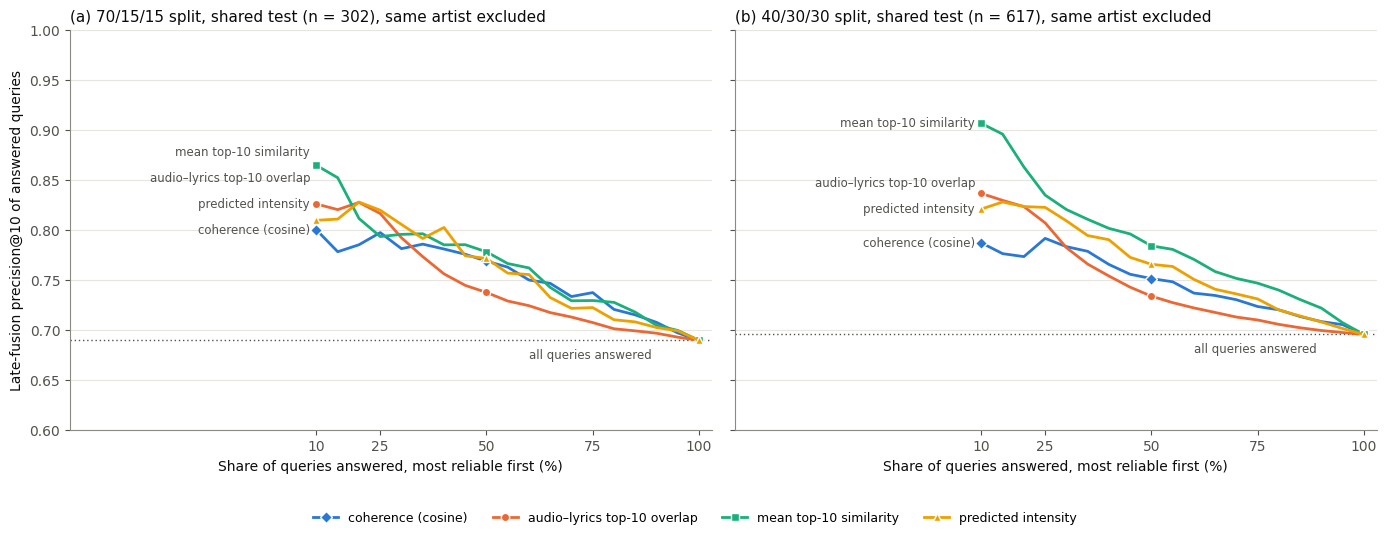

In [8]:
INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e0'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
                     'xtick.color': INK2, 'ytick.color': INK2, 'axes.labelcolor': INK, 'font.size': 10,
                     'axes.titlesize': 11, 'axes.titlecolor': INK, 'legend.frameon': False})
STY = {'coherence (cosine)':             dict(color='#2a78d6', marker='D', label='coherence (cosine)'),
       'top-10 list overlap':            dict(color='#eb6834', marker='o', label='audio–lyrics top-10 overlap'),
       'mean top-10 similarity (fused)': dict(color='#1baf7a', marker='s', label='mean top-10 similarity'),
       'predicted intensity':            dict(color='#eda100', marker='^', label='predicted intensity')}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
for ax, p, tag in zip(axes, ['70/15/15 test', '40/30/30 test'], 'ab'):
    t = selc[selc.population == p]; ends = []
    for s, st in STY.items():
        v = t[t.signal == s]
        ax.plot(v.coverage * 100, v['P@10'], color=st['color'], lw=2, marker=st['marker'], ms=6, mec='white', mew=1,
                markevery=[0, 8, 18], label=st['label'], zorder=3)
        ends.append((v['P@10'].values[0], st['label']))
    allq = QT[p].P10_fused.mean()
    ax.axhline(allq, color=INK2, lw=1, ls=(0, (1, 2)))
    ax.text(60, allq - 0.008, 'all queries answered', va='top', fontsize=8.5, color=INK2)
    ends.sort(); ys = []
    for y_, _ in ends:
        ys.append(max(y_, ys[-1] + 0.026) if ys else y_)
    for (y_, txt), yl in zip(ends, ys):
        ax.text(8.5, yl, txt, va='center', ha='right', fontsize=8.5, color=INK2)
    ax.set_xlim(-48, 103); ax.set_xticks([10, 25, 50, 75, 100]); ax.set_ylim(0.6, 1.0)
    ax.set_xlabel('Share of queries answered, most reliable first (%)')
    ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
    ax.set_title(f'({tag}) {p.split()[0]} split, shared test (n = {len(QT[p])}), same artist excluded', loc='left')
axes[0].set_ylabel('Late-fusion precision@10 of answered queries')
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig(os.path.join(OUT_DIR, 'coherence_selective_retrieval_af.png'), dpi=200, bbox_inches='tight'); plt.show()

## 4. Coherence-adaptive fusion weight

In [9]:
def adaptive(lbl, signal):
    val, te = shared[lbl]['validate'], shared[lbl]['test']
    QV = {a: query_table(lbl, val, a) for a in ALPHAS}
    # bins from the signal as computed at the fixed α = 0.6 (similarity-based signals depend on α)
    cuts = np.quantile(QV[0.6][signal].values, [1/3, 2/3])
    vb = np.digitize(QV[0.6][signal].values, cuts)
    assert all((vb == b).sum() >= 50 for b in range(3)), (signal, np.bincount(vb))
    best = {b: max(ALPHAS, key=lambda a: QV[a].P10_fused.values[vb == b].mean()) for b in range(3)}
    QTe = {a: query_table(lbl, te, a) for a in set(best.values()) | {0.6}}
    tb = np.digitize(QTe[0.6][signal].values, cuts)
    y_ad = np.select([tb == b for b in range(3)], [QTe[best[b]].P10_fused.values for b in range(3)])
    n_ad = np.select([tb == b for b in range(3)], [QTe[best[b]].nDCG10_fused.values for b in range(3)])
    return best, y_ad, n_ad, QTe[0.6]

arows = []
for lbl in SCHEMES.values():
    block = []
    for signal in ['coherence (cosine)', 'mean top-10 similarity (fused)']:
        best, y_ad, n_ad, fixed = adaptive(lbl, signal)
        for metric, a_, f_ in [('P@10', y_ad, fixed.P10_fused.values), ('nDCG@10', n_ad, fixed.nDCG10_fused.values)]:
            d = a_ - f_; lo, hi = boot_ci(d)
            pv = wilcoxon(a_, f_, zero_method='pratt').pvalue if (d != 0).any() else 1.0
            block.append({'split': lbl, 'signal': signal, 'alpha by tercile (low, mid, high)': tuple(best[b] for b in range(3)),
                          'metric': metric, 'adaptive': a_.mean(), 'fixed α=0.6': f_.mean(), 'diff': d.mean(), 'lo': lo, 'hi': hi, 'p': pv})
    for b, ph in zip(block, holm([b['p'] for b in block])):
        b['p_holm'] = ph
    arows += block
ad = pd.DataFrame(arows); ad.to_csv(os.path.join(OUT_DIR, 'coherence_checks_adaptive_alpha_af.csv'), index=False)
print(ad.to_string(index=False, float_format=lambda x: f'{x:.3g}'))
print('Saved: coherence_checks_*_af.csv, coherence_selective_retrieval_af.png')

   split                         signal alpha by tercile (low, mid, high)  metric  adaptive  fixed α=0.6    diff        lo       hi      p  p_holm
70/15/15             coherence (cosine)                   (0.6, 0.6, 0.6)    P@10      0.69         0.69       0         0        0      1       1
70/15/15             coherence (cosine)                   (0.6, 0.6, 0.6) nDCG@10     0.471        0.471       0         0        0      1       1
70/15/15 mean top-10 similarity (fused)                   (0.8, 0.6, 0.5)    P@10     0.676         0.69 -0.0136   -0.0265 -0.00132 0.0511   0.153
70/15/15 mean top-10 similarity (fused)                   (0.8, 0.6, 0.5) nDCG@10     0.461        0.471 -0.0102   -0.0175 -0.00318 0.0379   0.152
40/30/30             coherence (cosine)                   (0.6, 0.6, 0.6)    P@10     0.696        0.696       0         0        0      1       1
40/30/30             coherence (cosine)                   (0.6, 0.6, 0.6) nDCG@10     0.478        0.478       0      